# Graph neural networks for cybersecurity

**Goal:** Security data is full of graphs: system calls between processes and files, money flows between wallets, network flows between hosts, function calls inside a program.
This tutorial trains recent GNN architectures with **mlx-graphs** on four public security datasets, from self-supervised anomaly detection to node, edge and graph classification:

| | Task | Graph | Predict | Dataset | Models |
|---|---|---|---|---|---|
| 1 | Host intrusion detection | processes, files and sockets linked by system calls | anomalous nodes, without labels | DARPA TC E3 CADETS | Velox, Orthrus |
| 2 | Anti-money laundering | Bitcoin transactions linked by payments | node | Elliptic | MLP, GCN, GraphSAGE, GATv2, Graph Transformer, BWGNN |
| 3 | Network intrusion detection | hosts linked by NetFlow records | edge | NF-UNSW-NB15-v3 | MLP, E-GraphSAGE |
| 4 | Malware classification | Android function call graphs | graph | MalNet-Tiny | GIN, GraphGPS |

Along the way we write three layers that mlx-graphs does not ship (a beta-wavelet filter, an edge-feature message passing layer and a linear global attention) and look at the pitfalls that make security benchmarks look easier than they are: data snooping, time drift, shortcut features and class imbalance.

**Concepts:** `Self-supervised anomaly detection`, `Temporal neighbor sampling`, `Node, edge and graph classification`, `Custom MessagePassing layers`, `Custom Dataset`, `Temporal splits`, `Class imbalance`

**Requirements:** besides mlx-graphs, this notebook uses `pip install pandas pyarrow scikit-learn matplotlib gensim`. The datasets take about 2.2 GB of downloads, including 1.9 GB for CADETS, which you download by hand (see section 1).
Running the whole notebook takes about 45 minutes on an M5 Pro; lower `NUM_SEEDS` below to make sections 2 to 4 faster.

In [1]:
import os
import time
from math import comb

import matplotlib.pyplot as plt
import mlx.core as mx
import mlx.nn as nn
import mlx.optimizers as optim
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score

from mlx_graphs.data import GraphData
from mlx_graphs.loaders import Dataloader
from mlx_graphs.nn import Linear, MessagePassing, TransformerConv

# Each model is trained with NUM_SEEDS seeds and we report the mean and standard
# deviation: on these datasets, one run is not enough to rank two models.
NUM_SEEDS = 3

# MLX keeps freed buffers in a cache for reuse. Batches of graphs all have
# different shapes, so we cap that cache to keep the memory footprint small.
mx.set_cache_limit(1 << 30)


def mean_std(values):
    return f"{np.mean(values):.3f} ± {np.std(values):.3f}"

## 1. Host intrusion detection on provenance graphs (self-supervised anomaly detection)

An operating system can record every action of every process: which files a process reads and writes, which programs it executes, which network connections it opens. Linked together, these records form a **provenance graph**, where nodes are processes, files and network sockets, and edges are timestamped system events between them. An attack leaves a trace in this graph: a compromised web server that downloads and runs a payload adds new paths between processes, files and remote hosts.

**Provenance-based intrusion detection systems** (PIDSs) learn what normal activity looks like from a few days of benign provenance graphs, then flag the nodes that behave unusually. In this section, we build two recent PIDSs with mlx-graphs and evaluate them on the attacks of the DARPA Transparent Computing CADETS dataset:

- **Orthrus** ([Jiang et al., USENIX Security 2025](https://www.usenix.org/conference/usenixsecurity25/presentation/jiang-baoxiang)) embeds every node with a graph attention network (`TransformerConv`) over its most recent neighbors, and is trained to predict the type of each event from the embeddings of its two nodes. Events whose type the model cannot predict are anomalous.
- **Velox** ([Bilot et al., USENIX Security 2025](https://www.usenix.org/conference/usenixsecurity25/presentation/bilot)) keeps the same objective but replaces the graph neural network with a single linear layer. Bilot et al. show that this much simpler model is competitive with the state of the art, and trains in a fraction of the time.

We follow the preprocessing, hyperparameters and evaluation of [PIDSMaker](https://github.com/ubc-provenance/PIDSMaker), the framework released with the second paper, and its configurations without data snooping (`orthrus_non_snooped` and `velox`): the node features are learned from the training days only, and the detection threshold is set on a validation day without attacks.

![Pipeline: the CADETS audit records (CDM18 JSON) are parsed into a provenance graph of processes, files and netflows; repeated events are fused in 15-minute windows; word2vec embeds the node names; Velox (a linear layer) and Orthrus (TransformerConv over the 20 latest neighbors) both predict the type of every event; the cross-entropy of an event is its anomaly score, a node's score is the maximum over its events, and nodes above the highest validation score are flagged and compared with the ground truth of three attacks](../../assets/tutorials/provenance_intrusion_detection.svg)

In [2]:
import io
import json
import re
import tarfile
import urllib.request
import zipfile
import zlib
from array import array
from collections import defaultdict
from contextlib import redirect_stderr
from pathlib import Path

from gensim.models import Word2Vec

from mlx_graphs.metrics import average_precision_score, roc_auc_score
from mlx_graphs.nn.models.tgn import LastNeighborLoader

DATA_DIR = Path(".mlx_graphs_data/darpa_tc_e3_cadets")
SEED = 0
EPOCHS = 12
BATCH_SIZE = 1024  # edges per mini-batch
WINDOW_NS = 15 * 60 * 10**9  # 15-minute time windows
EMB_DIM = 256  # word2vec dimension
# CADETS E3 hyperparameters of PIDSMaker (docs/tuned_systems.md). For Orthrus,
# we keep the learning rate of its `orthrus_non_snooped` configuration (1e-4):
# with the tuned 1e-3, training sometimes diverged in our runs.
CONFIGS = {
    "Velox": dict(dim=256, lr=1e-4, dropout=0.3),
    "Orthrus": dict(dim=256, lr=1e-4, dropout=0.3),
}

### The dataset

In April 2018, the third engagement of the [DARPA Transparent Computing](https://github.com/darpa-i2o/Transparent-Computing) program recorded two weeks of activity on several hosts while a red team attacked them. **CADETS** is a FreeBSD web server, instrumented with DTrace. Its records follow DARPA's Common Data Model (CDM18): `Subject` records are processes, `FileObject` and `NetFlowObject` records are files and network flows, and `Event` records are system calls of a process on an object, with a timestamp in nanoseconds.

The red team attacked the Nginx web server of CADETS on April 6, 11, 12 and 13: it exploited a backdoor in Nginx, downloaded payloads such as `/tmp/main` and ran them. We use the node-level ground truth of Orthrus, distributed with PIDSMaker, which lists the malicious processes, files and netflows of each attack. As in PIDSMaker, we evaluate on the attacks of April 6, 12 and 13.

The records are published on Google Drive as three `.tar.gz` archives of JSON lines (1.9 GB in total). Google Drive limits the number of downloads per day, so download them by hand:

1. open the [CADETS folder](https://drive.google.com/drive/folders/179uDuz62Aw61Ehft6MoJCpPeBEz16VFy) of the DARPA release,
2. select the three JSON archives, `ta1-cadets-e3-official.json.tar.gz`, `ta1-cadets-e3-official-1.json.tar.gz` and `ta1-cadets-e3-official-2.json.tar.gz` (not the `.bin` ones),
3. click *Download*: Google Drive packs them into a single `drive-download-....zip`,
4. set `CADETS_ARCHIVE` below to the path of that zip.

The notebook reads the records directly from the zip, without extracting anything. The ground truth is downloaded from the PIDSMaker repository.

In [3]:
# Path of the zip downloaded from Google Drive: change it to yours
CADETS_ARCHIVE = Path(
    "~/Downloads/drive-download-20261121T130000Z-1-001.zip"
).expanduser()

GT_URL = (
    "https://raw.githubusercontent.com/ubc-provenance/PIDSMaker/main/"
    "Ground_Truth/orthrus/E3-CADETS/{}"
)
ATTACKS = {
    "Apr 6": "node_Nginx_Backdoor_06.csv",
    "Apr 12": "node_Nginx_Backdoor_12.csv",
    "Apr 13": "node_Nginx_Backdoor_13.csv",
}

with zipfile.ZipFile(CADETS_ARCHIVE) as z:
    ARCHIVES = sorted(n for n in z.namelist() if n.endswith(".json.tar.gz"))
assert len(ARCHIVES) == 3, f"expected the 3 CADETS JSON archives, found {ARCHIVES}"
print("\n".join(ARCHIVES))

for csv in ATTACKS.values():
    path = DATA_DIR / "ground_truth" / csv
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(GT_URL.format(csv), path)

ta1-cadets-e3-official-1.json.tar.gz
ta1-cadets-e3-official-2.json.tar.gz
ta1-cadets-e3-official.json.tar.gz


### From audit records to a provenance graph

We stream the JSON records out of the zip and its archives, without extracting them on disk, and keep:

- **nodes**: processes (`Subject`), files (`FileObject`, except Unix sockets, which Orthrus treats as netflows) and netflows (`NetFlowObject`). In CADETS, the name of a process and the path of a file are not in their own records but in the events that use them (the `exec` property and the `predicateObjectPath` field), so we collect them from the events, as Orthrus does. A netflow is named by its remote address and port.
- **edges**: the events of the 10 types used by Orthrus, from the process (`subject`) to the object (`predicateObject`). For the events through which information flows from the object to the process (`EXECUTE`, `OPEN`, `READ`, `RECVFROM`, `RECVMSG`), the edge is reversed.

Parsing the 44 million records takes about 3 minutes, so we cache the result.

In [4]:
CDM = "com.bbn.tc.schema.avro.cdm18."
EDGE_TYPES = [
    "EVENT_CONNECT",
    "EVENT_EXECUTE",
    "EVENT_OPEN",
    "EVENT_READ",
    "EVENT_RECVFROM",
    "EVENT_RECVMSG",
    "EVENT_SENDMSG",
    "EVENT_SENDTO",
    "EVENT_WRITE",
    "EVENT_CLONE",
]
EDGE_TYPE_ID = {name: i for i, name in enumerate(EDGE_TYPES)}
REVERSED = {
    "EVENT_EXECUTE",
    "EVENT_OPEN",
    "EVENT_READ",
    "EVENT_RECVFROM",
    "EVENT_RECVMSG",
}
NODE_TYPES = ["process", "file", "netflow"]
PROCESS, FILE, NETFLOW = 0, 1, 2


def iter_records(zip_path):
    # Yields the JSON lines of the three archives, streamed out of the zip.
    with zipfile.ZipFile(zip_path) as z:
        for archive in ARCHIVES:
            with z.open(archive) as f, tarfile.open(fileobj=f, mode="r|gz") as tar:
                for member in tar:
                    if member.isfile():
                        yield from tar.extractfile(member)


def parse_cadets(zip_path):
    uuid_to_id = {}

    def uid(uuid):
        return uuid_to_id.setdefault(uuid, len(uuid_to_id))

    node_type, netflow_name, exec_of, path_of = {}, {}, {}, {}
    src, dst, subject = array("q"), array("q"), array("q")
    etype, ts = array("b"), array("q")
    for line in iter_records(zip_path):
        kind = line[11 : line.index(b'"', 11)].decode().removeprefix(CDM)
        if kind not in ("Event", "Subject", "FileObject", "NetFlowObject"):
            continue
        d = json.loads(line)["datum"][CDM + kind]
        if kind == "Subject":
            node_type[uid(d["uuid"])] = PROCESS
        elif kind == "FileObject":
            i = uid(d["uuid"])
            if d["type"] == "FILE_OBJECT_UNIX_SOCKET":
                node_type[i], netflow_name[i] = NETFLOW, "unix socket"
            else:
                node_type[i] = FILE
        elif kind == "NetFlowObject":
            i = uid(d["uuid"])
            node_type[i] = NETFLOW
            netflow_name[i] = f"{d['remoteAddress']}:{d['remotePort']}"
        else:  # Event
            if d["subject"] is None or d["predicateObject"] is None:
                continue
            s = uid(d["subject"][CDM + "UUID"])
            o = uid(d["predicateObject"][CDM + "UUID"])
            exe = ((d["properties"] or {}).get("map") or {}).get("exec")
            if exe:
                exec_of[s] = exe
            path = d["predicateObjectPath"]
            if path is not None and path["string"] != "<unknown>":
                path_of[o] = path["string"]
            t = EDGE_TYPE_ID.get(d["type"])
            if t is None:
                continue
            subject.append(s)
            if d["type"] in REVERSED:
                s, o = o, s
            src.append(s)
            dst.append(o)
            etype.append(t)
            ts.append(d["timestampNanos"])

    types = np.full(len(uuid_to_id), -1, dtype=np.int8)  # -1: not a node
    types[list(node_type)] = list(node_type.values())
    names = [""] * len(uuid_to_id)
    for i, t in node_type.items():
        names[i] = (exec_of, path_of, netflow_name)[t].get(i) or ""
    arrays = dict(src=src, dst=dst, subject=subject, edge_type=etype, t=ts)
    arrays = {k: np.frombuffer(v, dtype=v.typecode).copy() for k, v in arrays.items()}
    return arrays, types, list(uuid_to_id), names


CACHE = DATA_DIR / "processed"
if not (CACHE / "events.npz").exists():
    start = time.perf_counter()
    arrays, types, uuids, names = parse_cadets(CADETS_ARCHIVE)
    print(f"Parsed in {time.perf_counter() - start:.0f} s")
    CACHE.mkdir(parents=True, exist_ok=True)
    np.savez(CACHE / "events.npz", node_type=types, **arrays)
    (CACHE / "nodes.json").write_text(json.dumps({"uuid": uuids, "name": names}))
    del arrays, types, uuids, names

events = dict(np.load(CACHE / "events.npz"))
objects = json.loads((CACHE / "nodes.json").read_text())
print(f"{len(objects['uuid']):,} objects, {events['t'].size:,} events")

2,741,785 objects, 18,893,277 events


#### Splits, time windows and edge fusion

PIDSMaker splits CADETS by day, in the US/Eastern time zone of the engagement. The days without attacks are used for training (April 2 to 5 and 7 to 9) and validation (April 10), and the four days with attacks for testing.

A process often repeats the same system call on the same object, e.g. hundreds of `READ`s of one file. Like Orthrus, we cut the stream into 15-minute windows and, inside each window, fuse the consecutive events of the same type between the same two nodes into the first one. This divides the number of edges by more than 3 without changing the structure of the graph.

In [5]:
SPLITS = {
    "train": [
        "2018-04-02",
        "2018-04-03",
        "2018-04-04",
        "2018-04-05",
        "2018-04-07",
        "2018-04-08",
        "2018-04-09",
    ],
    "val": ["2018-04-10"],
    "test": ["2018-04-06", "2018-04-11", "2018-04-12", "2018-04-13"],
}
TRAIN, VAL, TEST = 0, 1, 2

node_type = events["node_type"]
src, dst, etype, t, subject = (
    events[k] for k in ("src", "dst", "edge_type", "t", "subject")
)

# Keep the events of a process on a process, a file or a netflow
obj = np.where(subject == src, dst, src)
keep = (node_type[subject] == PROCESS) & (node_type[obj] >= 0)

# Day of every event in the US/Eastern time zone
day = pd.to_datetime(t, utc=True).tz_convert("US/Eastern").tz_localize(None)
day = day.to_numpy().astype("datetime64[D]")
split = np.full(t.size, -1, dtype=np.int8)
for k, dates in enumerate(SPLITS.values()):
    split[np.isin(day, np.array(dates, dtype="datetime64[D]"))] = k
keep &= split >= 0
src, dst, etype, t, split = (a[keep] for a in (src, dst, etype, t, split))
del events, day, subject, obj, keep
print(f"{t.size:,} events between processes, files and netflows")

# Edge fusion inside 15-minute windows
window = (t - t.min()) // WINDOW_NS
order = np.lexsort((t, dst, src, window))  # by window, edge, then time
w, s, d, e = window[order], src[order], dst[order], etype[order]
first = np.ones(order.size, dtype=bool)
first[1:] = (
    (w[1:] != w[:-1]) | (s[1:] != s[:-1]) | (d[1:] != d[:-1]) | (e[1:] != e[:-1])
)
kept = order[first]
kept = kept[np.argsort(t[kept], kind="stable")]  # back to time order
src, dst, etype, t, split, window = (
    a[kept] for a in (src, dst, etype, t, split, window)
)
del w, s, d, e, order, first, kept
print(f"{t.size:,} edges after fusion")

# Relabel the nodes 0..num_nodes-1
used, inverse = np.unique(np.concatenate([src, dst]), return_inverse=True)
src, dst = inverse[: src.size], inverse[src.size :]
num_nodes = used.size
ntype = node_type[used].astype(np.int64)
name = [objects["name"][i] for i in used]
node_of_uuid = {objects["uuid"][i]: k for k, i in enumerate(used)}

print(
    f"{num_nodes:,} nodes: "
    + ", ".join(
        f"{np.sum(ntype == k):,} {n}es"
        if n == "process"
        else f"{np.sum(ntype == k):,} {n}s"
        for k, n in enumerate(NODE_TYPES)
    )
)
pd.DataFrame(
    {
        "days": [len(v) for v in SPLITS.values()],
        "edges": [int(np.sum(split == k)) for k in range(3)],
    },
    index=list(SPLITS),
)

18,699,410 events between processes, files and netflows


5,688,677 edges after fusion


643,486 nodes: 209,587 processes, 233,699 files, 200,200 netflows


,days,edges
train,7,3229340
val,1,501962
test,4,1957375


### Node features

The name of a node says a lot about it: `/usr/local/sbin/nginx` is not `/tmp/main`, and `81.49.200.166:80` is not a local DNS server. Orthrus turns these names into vectors with **word2vec**. A name is split into tokens (`/`, `usr`, `/`, `local`, ... for a path, the bytes of an address separated by `.` and `:` for a netflow), word2vec learns a vector for every token from the names of the training nodes, and a node is embedded as the weighted mean of its token vectors, with weights that decrease along the name. Tokens never seen in training, which only appear in the test days, get a zero vector. The node type is appended as a one-hot vector.

In [6]:
def tokenize(text, kind):
    if kind == NETFLOW:
        return text.replace(":", " : ").replace(".", " . ").split()
    return re.sub(r"\\+", "/", text).replace("/", " / ").split()


tokens = [tokenize(n, k) for n, k in zip(name, ntype)]

# Corpus: the distinct names of the nodes seen during training
train_nodes = np.unique(np.concatenate([src[split == TRAIN], dst[split == TRAIN]]))
corpus = list({name[i]: tokens[i] for i in train_nodes if tokens[i]}.values())

# gensim 4.4 declares the BLAS dot product with `except -1`, so every dot product
# equal to -1.0 prints "Exception ignored in ... our_dot_float" to sys.stderr.
# The value is correct: we hide these messages while training.
start = time.perf_counter()
with redirect_stderr(io.StringIO()):
    w2v = Word2Vec(
        corpus,
        vector_size=EMB_DIM,
        window=5,
        min_count=1,
        sg=1,  # skip-gram
        negative=5,
        alpha=0.025,
        epochs=50,
        workers=1,
        seed=SEED,
        hashfxn=lambda s: zlib.crc32(s.encode()),  # reproducible initialization
    )
print(
    f"word2vec: {len(corpus):,} names, {len(w2v.wv):,} tokens, "
    f"trained in {time.perf_counter() - start:.0f} s"
)


def embed(toks, decline=0.3):
    # Weighted mean of the token vectors, as in Orthrus.
    if not toks:
        return np.zeros(EMB_DIM)
    n = len(toks)
    step = -decline / n
    weights = 1 / n - 0.5 * (n - 1) * step + step * np.arange(n)
    vecs = np.stack([w2v.wv[w] if w in w2v.wv else np.zeros(EMB_DIM) for w in toks])
    v = (weights[:, None] * vecs).mean(axis=0)
    return v / (np.linalg.norm(v) + 1e-12)


features = np.zeros((num_nodes, EMB_DIM + len(NODE_TYPES)), dtype=np.float32)
for i, tk in enumerate(tokens):
    features[i, :EMB_DIM] = embed(tk)
features[np.arange(num_nodes), EMB_DIM + ntype] = 1.0  # one-hot node type
X = mx.array(features)
del features, tokens, corpus, objects  # free host memory
print(X.shape)

word2vec: 181,917 names, 102,676 tokens, trained in 161 s


(643486, 259)


### Ground truth

Each ground-truth file lists the UUIDs of the malicious nodes of one attack. A few of them never appear in an edge we keep, and cannot be detected.

In [7]:
attack_nodes = {}
for attack, csv in ATTACKS.items():
    uuids = pd.read_csv(DATA_DIR / "ground_truth" / csv, header=None)[0]
    attack_nodes[attack] = {node_of_uuid[u] for u in uuids if u in node_of_uuid}
    print(
        f"{attack}: {len(uuids)} malicious nodes, "
        f"{len(attack_nodes[attack])} in the graph"
    )
malicious = set().union(*attack_nodes.values())

Apr 6: 8 malicious nodes, 8 in the graph
Apr 12: 43 malicious nodes, 41 in the graph
Apr 13: 24 malicious nodes, 22 in the graph


### Two detectors with the same objective

Both systems are **self-supervised**: they never see an attack during training. They learn to predict the type of every event (`READ`, `WRITE`, `CONNECT`, ...) from its two nodes. On benign activity, an event's type is predictable: `nginx` reads its configuration files and sends to remote clients. The cross-entropy of an event is its anomaly score, and an event the model cannot explain gets a high score.

The two systems share the decoder, an MLP on the concatenation of the projected source and destination embeddings, and differ in the encoder:

- **Velox** embeds a node by a single linear layer of its features. The embedding of a node does not depend on the graph at all.
- **Orthrus** embeds a node by two `TransformerConv` layers (8 heads, then 1) over its recent neighborhood. A `LastNeighborLoader` keeps the 20 most recent neighbors of every node, and each edge carries the one-hot type of the event as edge features. The embedding of a node therefore depends on what it did recently.

In [8]:
NUM_TYPES = len(EDGE_TYPES)
EDGE_ONE_HOT = mx.eye(NUM_TYPES)


class EdgeTypeDecoder(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.lin_src = nn.Linear(dim, 2 * dim)
        self.lin_dst = nn.Linear(dim, 2 * dim)
        self.mlp = nn.Sequential(
            nn.Linear(4 * dim, 2 * dim), nn.ReLU(), nn.Linear(2 * dim, NUM_TYPES)
        )

    def __call__(self, h_src, h_dst):
        return self.mlp(
            mx.concatenate([self.lin_src(h_src), self.lin_dst(h_dst)], axis=-1)
        )


class Velox(nn.Module):
    def __init__(self, in_dim, dim, dropout):
        super().__init__()
        self.encoder = nn.Linear(in_dim, dim)
        self.dropout = nn.Dropout(dropout)
        self.decoder = EdgeTypeDecoder(dim)

    def __call__(self, batch_src, batch_dst):
        h_src = self.dropout(self.encoder(X[batch_src]))
        h_dst = self.dropout(self.encoder(X[batch_dst]))
        return self.decoder(h_src, h_dst)


class Orthrus(nn.Module):
    def __init__(self, in_dim, dim, dropout, proj_dim=100, heads=8):
        super().__init__()
        self.proj = nn.Linear(in_dim, proj_dim)
        self.conv1 = TransformerConv(
            proj_dim, dim, heads=heads, dropout=dropout, edge_features_dim=NUM_TYPES
        )
        self.conv2 = TransformerConv(
            heads * dim,
            dim,
            heads=1,
            concat=False,
            dropout=dropout,
            edge_features_dim=NUM_TYPES,
        )
        self.dropout = nn.Dropout(dropout)
        self.decoder = EdgeTypeDecoder(dim)

    def __call__(self, n_id, edge_index, edge_types, batch_src, batch_dst):
        # n_id: the batch nodes and their recent neighbors; batch_src/dst: local ids
        e = EDGE_ONE_HOT[edge_types]
        h = self.proj(X[n_id])
        h = self.dropout(nn.relu(self.conv1(edge_index, h, e)))
        h = self.conv2(edge_index, h, e)
        return self.decoder(h[batch_src], h[batch_dst])

#### Mini-batches and neighborhoods

The edges are processed in time order, in mini-batches of 1,024 edges that do not cross a 15-minute window. For Orthrus, `Neighborhood` asks the `LastNeighborLoader` for the recent neighbors of the batch's nodes, and maps the batch's edges to the local indexing of that subgraph. The batch's own edges are inserted into the loader only after the batch is processed, so the model never sees the type of an event before predicting it.

In [9]:
ETYPE = mx.array(etype.astype(np.int32))


def batches(mask):
    # Chronological batches of BATCH_SIZE edges that do not cross a 15-min window.
    idx = np.flatnonzero(mask)
    out = []
    for chunk in np.split(idx, np.flatnonzero(np.diff(window[idx])) + 1):
        out.extend(np.split(chunk, np.arange(BATCH_SIZE, chunk.size, BATCH_SIZE)))
    return out


class Neighborhood:
    # Recent neighborhood of the batches of a stream of edges.

    def __init__(self, stream):
        self.loader = LastNeighborLoader(num_nodes, size=20)
        self.stream = stream  # edge id of the i-th edge inserted in the loader
        self.assoc = np.zeros(num_nodes, dtype=np.int64)

    def __call__(self, b):
        n_id, edge_index, e_id = self.loader(
            np.unique(np.concatenate([src[b], dst[b]]))
        )
        self.assoc[np.array(n_id)] = np.arange(n_id.size)
        edge_types = ETYPE[mx.array(self.stream[np.array(e_id)].astype(np.int32))]

        def local(nodes):
            return mx.array(self.assoc[nodes].astype(np.int32))

        return n_id, edge_index, edge_types, local(src[b]), local(dst[b])

    def insert(self, b):
        self.loader.insert(src[b], dst[b])


def inputs(model, neighborhood, b):
    if isinstance(model, Orthrus):
        return neighborhood(b)
    return mx.array(src[b].astype(np.int32)), mx.array(dst[b].astype(np.int32))


def loss_fn(model, x, y):
    return nn.losses.cross_entropy(model(*x), y, reduction="mean")


def train_epoch(model, optimizer, train_batches):
    model.train()
    neighborhood = Neighborhood(np.concatenate(train_batches))
    loss_and_grad = nn.value_and_grad(model, loss_fn)
    total = 0.0
    for b in train_batches:
        loss, grads = loss_and_grad(
            model, inputs(model, neighborhood, b), ETYPE[mx.array(b)]
        )
        optimizer.update(model, grads)
        mx.eval(model.parameters(), optimizer.state, loss)
        neighborhood.insert(b)
        total += loss.item() * b.size
    return total / sum(b.size for b in train_batches)


def edge_scores(model, all_batches):
    # Anomaly score (cross-entropy) of every edge, replaying the whole stream.
    model.eval()
    neighborhood = Neighborhood(np.concatenate(all_batches))
    scores = np.zeros(t.size, dtype=np.float32)
    for b in all_batches:
        logits = model(*inputs(model, neighborhood, b))
        loss = nn.losses.cross_entropy(logits, ETYPE[mx.array(b)], reduction="none")
        scores[b] = np.array(loss)
        neighborhood.insert(b)
    return scores


train_batches = batches(split == TRAIN)
all_batches = batches(np.ones(t.size, dtype=bool))
print(f"{len(train_batches):,} training batches, {len(all_batches):,} batches in total")

3,440 training batches, 6,051 batches in total


### Training

We train each model for 12 epochs with Adam, and time every epoch. After training, the whole stream (training, validation and test days, in time order) is replayed once to score every edge.

In [10]:
def run(name, seed=SEED):
    cfg = CONFIGS[name]
    mx.random.seed(seed)
    model = {"Velox": Velox, "Orthrus": Orthrus}[name](
        X.shape[1], cfg["dim"], cfg["dropout"]
    )
    optimizer = optim.Adam(learning_rate=cfg["lr"], bias_correction=True)
    epoch_s = []
    for epoch in range(1, EPOCHS + 1):
        start = time.perf_counter()
        loss = train_epoch(model, optimizer, train_batches)
        epoch_s.append(time.perf_counter() - start)
        print(f"{name} epoch {epoch:02d}  loss {loss:.4f}  {epoch_s[-1]:.1f} s")
    start = time.perf_counter()
    scores = edge_scores(model, all_batches)
    return dict(scores=scores, epoch_s=epoch_s, score_s=time.perf_counter() - start)


runs = {"Velox": run("Velox")}

Velox epoch 01  loss 0.5580  5.1 s


Velox epoch 02  loss 0.4784  5.0 s


Velox epoch 03  loss 0.4657  5.1 s


Velox epoch 04  loss 0.4555  5.4 s


Velox epoch 05  loss 0.4451  5.4 s


Velox epoch 06  loss 0.4415  5.3 s


... (2 outputs left out)

Velox epoch 09  loss 0.4381  5.8 s


Velox epoch 10  loss 0.4364  5.3 s


Velox epoch 11  loss 0.4356  5.1 s


Velox epoch 12  loss 0.4350  5.2 s


In [11]:
runs["Orthrus"] = run("Orthrus")

Orthrus epoch 01  loss 0.4872  43.4 s


Orthrus epoch 02  loss 0.4492  41.6 s


Orthrus epoch 03  loss 0.4404  46.5 s


Orthrus epoch 04  loss 0.4316  47.9 s


Orthrus epoch 05  loss 0.4274  52.1 s


Orthrus epoch 06  loss 0.4258  55.5 s


... (2 outputs left out)

Orthrus epoch 09  loss 0.4255  52.6 s


Orthrus epoch 10  loss 0.4254  49.6 s


Orthrus epoch 11  loss 0.4267  51.1 s


Orthrus epoch 12  loss 0.4233  49.2 s


### Detection

A node's anomaly score is the highest score of its test edges, as a source or a destination. The threshold is the highest edge score of the validation day: on a day without attacks, nothing should be flagged. The test nodes above the threshold are the alerts.

Besides the counts of true and false positives, we report the metrics of Bilot et al.:

- **precision** and **MCC** of the alerts,
- **attacks detected**: the number of attacks with at least one true positive. A security analyst who receives an alert on one malicious node can then trace the rest of the attack.
- **ADP** (attack detection precision): the area under the curve of the percentage of attacks detected against the precision, when the threshold goes down the ranking. It is 1 when, for each attack, a malicious node is ranked above all benign nodes.

We also report the ROC AUC and the average precision of the node scores, which do not depend on the threshold.

In [12]:
test = split == TEST
test_nodes = np.unique(np.concatenate([src[test], dst[test]]))
y_true = np.isin(test_nodes, list(malicious))


def node_scores(scores):
    out = np.zeros(num_nodes, dtype=np.float32)
    np.maximum.at(out, src[test], scores[test])
    np.maximum.at(out, dst[test], scores[test])
    return out[test_nodes]


def adp(node_score):
    # Area under (precision, % of attacks detected) along the ranking.
    best = defaultdict(float, {0.0: 0.0})
    tp = fp = 0
    found = set()
    for k in np.argsort(-node_score, kind="stable"):
        node = test_nodes[k]
        if y_true[k]:
            tp += 1
            found |= {a for a, nodes in attack_nodes.items() if node in nodes}
        else:
            fp += 1
        precision = tp / (tp + fp)
        best[precision] = max(best[precision], len(found) / len(attack_nodes))
    xs = sorted(best)
    return float(np.trapezoid([best[x] for x in xs], xs))


def evaluate(scores):
    threshold = scores[split == VAL].max()
    node_score = node_scores(scores)
    y_pred = node_score > threshold
    tp, fp = int(np.sum(y_true & y_pred)), int(np.sum(~y_true & y_pred))
    fn, tn = int(np.sum(y_true & ~y_pred)), int(np.sum(~y_true & ~y_pred))
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    flagged = set(test_nodes[y_pred])
    detected = sum(bool(nodes & flagged) for nodes in attack_nodes.values())
    return {
        "threshold": round(float(threshold), 2),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": round(tp / max(tp + fp, 1), 3),
        "MCC": round((tp * tn - fp * fn) / denom if denom else 0.0, 3),
        "attacks detected": f"{detected}/{len(attack_nodes)}",
        "ADP": round(adp(node_score), 3),
        "ROC AUC": round(roc_auc_score(y_true, node_score), 3),
        "AP": round(average_precision_score(y_true, node_score), 3),
    }


print(f"{test_nodes.size:,} test nodes, {y_true.sum()} malicious")
results = pd.DataFrame({name: evaluate(r["scores"]) for name, r in runs.items()}).T
results

281,583 test nodes, 68 malicious


,threshold,TP,FP,FN,precision,MCC,attacks detected,ADP,ROC AUC,AP
Velox,8.74,39,23,29,0.629,0.601,3/3,0.965,0.816,0.539
Orthrus,11.82,24,17,44,0.585,0.454,3/3,0.75,0.816,0.307


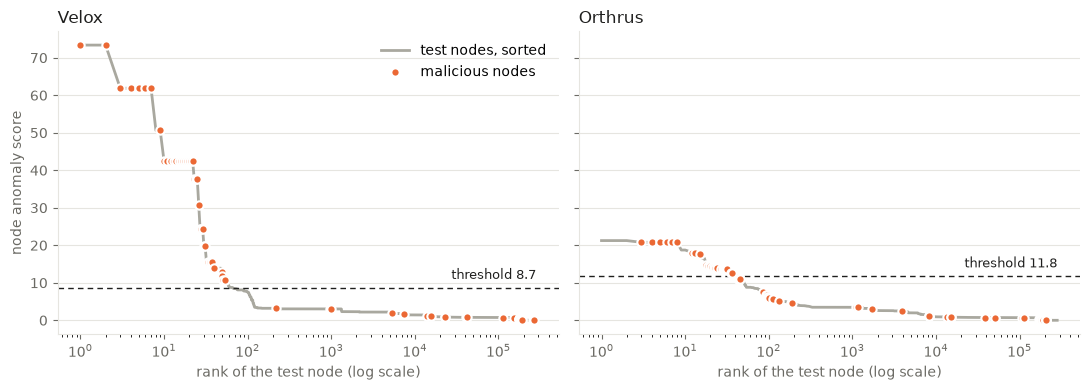

In [13]:
ALERT, INK, MUTED, GRID, CURVE = "#eb6834", "#1f1f1e", "#6b6a64", "#e6e5e0", "#a9a89f"

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (model, r) in zip(axes, runs.items()):
    node_score = node_scores(r["scores"])
    order = np.argsort(-node_score)
    rank = np.arange(1, order.size + 1)
    ax.plot(
        rank, node_score[order], color=CURVE, linewidth=2, label="test nodes, sorted"
    )
    bad = y_true[order]
    ax.scatter(
        rank[bad],
        node_score[order][bad],
        s=36,
        color=ALERT,
        edgecolor="white",
        linewidth=1.5,
        zorder=3,
        label="malicious nodes",
    )
    threshold = float(results.loc[model, "threshold"])
    ax.axhline(threshold, color=INK, linewidth=1, linestyle=(0, (4, 3)))
    ax.annotate(
        f"threshold {threshold:.1f}",
        (order.size, threshold),
        xytext=(0, 4),
        textcoords="offset points",
        ha="right",
        va="bottom",
        color=INK,
        fontsize=9,
    )
    ax.set_xscale("log")
    ax.set_title(model, loc="left", color=INK)
    ax.set_xlabel("rank of the test node (log scale)", color=MUTED)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
axes[0].set_ylabel("node anomaly score", color=MUTED)
axes[0].legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

**Both detectors find the three attacks.** Velox raises 62 alerts, 39 of them on malicious nodes (precision 0.63), and ranks the April 12 attack first: the files `/tmp/main` and `/tmp/test` that the red team wrote, and the processes that ran them. The payload of April 6, `/tmp/vUgefal`, follows in its top 15. Orthrus raises 41 alerts, 24 of them malicious (precision 0.59). It ranks a benign `sh` shell and `/etc/motd` first, then nodes of the three attacks, such as the payloads `/tmp/pEja72mA` and `/tmp/vUgefal`, in ranks 3 to 8, hence an ADP of 0.75 against 0.965 for Velox. The other false positives near the top are benign processes and objects such as `sshd` sessions or a Unix socket.

About half of the malicious nodes stay below the threshold (recall 0.57 for Velox, 0.35 for Orthrus): they are nodes that the attacks used but whose events look ordinary. This is less of a problem than it seems. One alert per attack is enough for an analyst to start an investigation, and to trace the rest of the attack in the provenance graph.

These numbers vary from run to run: the order of the floating-point additions on the GPU changes the training of Orthrus slightly, and Bilot et al. report that PIDSs are unstable in general. In another run of this notebook, Orthrus ranked nodes of the three attacks first, with an ADP of 1. To measure the variation, train with several seeds with `run(name, seed=...)`.

In [14]:
timing = pd.DataFrame(
    {
        name: {
            "s/epoch (median)": round(float(np.median(r["epoch_s"])), 1),
            "training (s)": round(float(np.sum(r["epoch_s"])), 1),
            "scoring (s)": round(r["score_s"], 1),
        }
        for name, r in runs.items()
    }
).T
timing

,s/epoch (median),training (s),scoring (s)
Velox,5.3,63.6,3.0
Orthrus,50.4,599.6,32.1


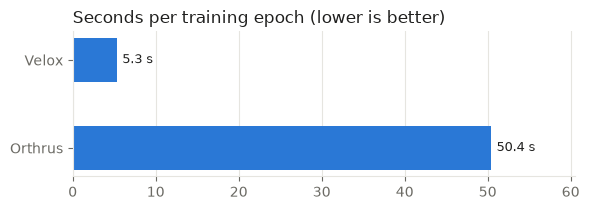

In [15]:
fig, ax = plt.subplots(figsize=(6, 2.2))
names = list(timing.index)
values = timing["s/epoch (median)"].to_numpy()
bars = ax.barh(names, values, height=0.5, color="#2a78d6")
for bar, value in zip(bars, values):
    ax.annotate(
        f"{value:.1f} s",
        (value, bar.get_y() + bar.get_height() / 2),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        color=INK,
        fontsize=9,
    )
ax.invert_yaxis()
ax.set_title("Seconds per training epoch (lower is better)", loc="left", color=INK)
ax.set_xlim(0, values.max() * 1.2)
ax.tick_params(colors=MUTED)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(GRID)
fig.tight_layout()
plt.show()

**Runtime.** On an Apple M5 Pro, Velox trains about 10 times faster than Orthrus (5.3 s against 50.4 s per epoch) and scores the whole stream in 3 s instead of 32 s, and its detection is at least as good. Orthrus does much more work per batch: it gathers the 20 latest neighbors of the batch's nodes from the `LastNeighborLoader` and runs an 8-head attention over them, where Velox multiplies the features of each node by one matrix. This is the finding of Bilot et al.: on these datasets, a model without message passing can match a graph neural network, at a fraction of the cost.

### What an analyst sees

The alerts are a ranked list of nodes. Below are the 15 highest-ranked test nodes of each model, with their name and whether they belong to an attack.

In [16]:
def top_nodes(scores, k=15):
    node_score = node_scores(scores)
    rows = []
    for j in np.argsort(-node_score)[:k]:
        node = test_nodes[j]
        attack = [a for a, nodes in attack_nodes.items() if node in nodes]
        rows.append(
            {
                "score": round(float(node_score[j]), 2),
                "type": NODE_TYPES[ntype[node]],
                "name": name[node][:60],
                "attack": attack[0] if attack else "",
            }
        )
    return pd.DataFrame(rows, index=pd.RangeIndex(1, k + 1, name="rank"))


top_nodes(runs["Velox"]["scores"])

,score,type,name,attack
rank,,,,
1,73.37,process,main,Apr 12
2,73.37,file,/tmp/main,Apr 12
3,61.86,process,test,Apr 12
4,61.86,process,test,Apr 12
5,61.86,file,/tmp/test,Apr 12
6,61.86,process,test,Apr 12
7,61.86,process,test,Apr 12
8,50.61,process,sshd,
9,50.61,file,/tmp/font,Apr 12


In [17]:
top_nodes(runs["Orthrus"]["scores"])

,score,type,name,attack
rank,,,,
1,21.25,process,sh,
2,21.25,file,/etc/motd,
3,20.79,file,/tmp/pEja72mA,Apr 13
4,20.79,process,tmux-1002,Apr 12
5,20.79,file,/tmp/tmux-1002,Apr 12
6,20.79,file,/tmp/vUgefal,Apr 6
7,20.79,process,vUgefal,Apr 6
8,20.79,process,pEja72mA,Apr 13
9,18.73,netflow,unix socket,


### Going further

- PIDSMaker implements these two systems and seven others (Kairos, Magic, Flash, NodLink, ThreaTrace, R-Caid, ...) on the DARPA E3 and E5 datasets and on OpTC, with the same preprocessing and evaluation. The configurations used here are `orthrus_non_snooped` and `velox`.
- The same code runs on the other DARPA TC E3 hosts (THEIA, CLEARSCOPE) after adapting the parser to their records.
- Orthrus goes on from the alerts to reconstruct each attack by dependency analysis over the provenance graph. With mlx-graphs, the subgraph around an alert can be extracted with `mlx_graphs.utils.k_hop_subgraph`.

In [18]:
# The next sections do not use the provenance graph: release its memory
X = ETYPE = runs = train_batches = all_batches = None
src = dst = etype = t = split = window = name = node_of_uuid = None
mx.clear_cache()

## 2. Anti-money laundering on Bitcoin (node classification)

The [Elliptic dataset](https://arxiv.org/abs/1908.02591) (Weber et al., 2019) is a graph of 203,769 Bitcoin transactions (nodes) and 234,355 payment flows (edges) over 49 time steps, about two weeks apart.
About 2% of the transactions are labelled **illicit** (scams, ransomware, darknet markets, ...), 21% **licit** (exchanges, miners, wallet providers, ...), and the rest are unknown.
The task is to flag illicit transactions, and the metric is the F1 score of the illicit class.

mlx-graphs ships the dataset as `EllipticBitcoinDataset`. The first call downloads and processes the raw CSV files, which takes a few minutes.

In [19]:
from mlx_graphs.datasets import EllipticBitcoinDataset

elliptic = EllipticBitcoinDataset()
tx_graph = elliptic[0]
tx_graph

Loading ellipticBitcoin data ... Done


GraphData(
	edge_index(shape=(2, 234355), int64)
	node_features(shape=(203769, 165), float32)
	node_labels(shape=(203769,), int64)
	train_mask(shape=(203769,), bool)
	test_mask(shape=(203769,), bool))

Labels are `0` (licit), `1` (illicit) and `2` (unknown). The time step of each transaction is the second column of the raw features file.

We split the data **by time**, as the paper does: train on time steps 1–30, select models on 31–34 and test on 35–49.
A random split would let the model see the future, and it would hide the main difficulty of this dataset, which is that criminal behaviour changes over time.

In [20]:
time_step = pd.read_csv(
    os.path.join(elliptic.raw_path, "elliptic_txs_features.csv"),
    header=None,
    usecols=[1],
)[1].to_numpy()

tx_labels = tx_graph.node_labels
y_tx = np.array(tx_labels)
known = y_tx != 2

# MLX indexes arrays with integer indices rather than boolean masks
tx_splits = {
    "train": np.nonzero(known & (time_step <= 30))[0],
    "val": np.nonzero(known & (time_step > 30) & (time_step <= 34))[0],
    "test": np.nonzero(known & (time_step >= 35))[0],
}
pd.DataFrame(
    {
        name: {
            "transactions": len(idx),
            "illicit": int((y_tx[idx] == 1).sum()),
            "illicit %": round(100 * (y_tx[idx] == 1).mean(), 1),
        }
        for name, idx in tx_splits.items()
    }
).T

,transactions,illicit,illicit %
train,26905.0,2954.0,11.0
val,2989.0,508.0,17.0
test,16670.0,1083.0,6.5


Each transaction has 165 features: 93 **local** features (amounts, fees, number of inputs and outputs, ...) and 72 **aggregated** features, which the dataset authors computed from the transaction's neighbours (maxima, minima, standard deviations, ...).
The aggregated features are a hand-made one-hop message passing step. To see what message passing learns on its own, we first give the models only the 93 local features, and come back to the aggregated ones later.

Money flows in one direction, but whether a transaction pays or is paid by a suspicious one is informative either way, so we make the graph undirected.

In [21]:
from mlx_graphs.utils import to_undirected

x_local = tx_graph.node_features[:, :93]
x_all = tx_graph.node_features
tx_edge_index = to_undirected(tx_graph.edge_index.astype(mx.int32))
print(f"{x_local.shape[0]} transactions, {tx_edge_index.shape[1]} directed edges")

203769 transactions, 468710 directed edges


### Models

Every GNN below has the same shape: a linear layer encodes the features, two message passing layers mix in the neighbourhood, and a classifier reads the concatenation of the encoded features and the GNN output.
The skip connection lets a model fall back on the transaction's own features when its neighbours say little: transactions have 2.3 neighbours on average, and most of them are unlabelled.

The layers range from the classic to more recent ones:

* [GCN](https://arxiv.org/abs/1609.02907) (Kipf & Welling, 2017), the baseline of the Elliptic paper;
* [GraphSAGE](https://arxiv.org/abs/1706.02216) (Hamilton et al., 2017), which keeps a separate weight for the node itself;
* [GATv2](https://arxiv.org/abs/2105.14491) (Brody et al., 2022), attention whose ranking of neighbours depends on the node attending;
* the Graph Transformer layer of [UniMP](https://arxiv.org/abs/2009.03509) (Shi et al., 2021), with a gate (`beta=True`) between the node and its neighbours.

They all come with mlx-graphs and share the `conv(edge_index, node_features)` interface.

In [22]:
from mlx_graphs.nn import GATv2Conv, GCNConv, SAGEConv


class MLP(nn.Module):
    # Baseline that ignores the graph
    def __init__(self, in_dim, hidden, out_dim=2, dropout=0.2):
        super().__init__()
        self.lin1 = Linear(in_dim, hidden)
        self.lin2 = Linear(hidden, hidden)
        self.out = Linear(hidden, out_dim)
        self.dropout = nn.Dropout(dropout)

    def __call__(self, edge_index, x):
        h = self.dropout(nn.relu(self.lin1(x)))
        h = self.dropout(nn.relu(self.lin2(h)))
        return self.out(h)


def make_conv(kind, in_dim, out_dim, heads=4):
    if kind == "gcn":
        return GCNConv(in_dim, out_dim)
    if kind == "sage":
        return SAGEConv(in_dim, out_dim)
    if kind == "gatv2":
        return GATv2Conv(in_dim, out_dim // heads, heads=heads)
    if kind == "transformer":
        return TransformerConv(in_dim, out_dim // heads, heads=heads, beta=True)
    raise ValueError(kind)


class GNN(nn.Module):
    def __init__(self, kind, in_dim, hidden, out_dim=2, dropout=0.2):
        super().__init__()
        self.encoder = Linear(in_dim, hidden)
        self.conv1 = make_conv(kind, hidden, hidden)
        self.conv2 = make_conv(kind, hidden, hidden)
        self.out = Linear(2 * hidden, out_dim)
        self.dropout = nn.Dropout(dropout)

    def __call__(self, edge_index, x):
        h0 = self.dropout(nn.relu(self.encoder(x)))
        h = self.dropout(nn.relu(self.conv1(edge_index, h0)))
        h = self.dropout(nn.relu(self.conv2(edge_index, h)))
        return self.out(mx.concatenate([h0, h], axis=-1))

#### A spectral anomaly detector: BWGNN

[BWGNN](https://arxiv.org/abs/2205.15508) (Tang et al., ICML 2022) starts from an observation about anomalies: they shift the spectral energy of the graph signal towards high frequencies, which low-pass filters such as GCN smooth away.
It therefore filters the node embeddings $h$ with a bank of $C + 1$ **beta wavelets**, from low-pass to high-pass, and concatenates the results:

$$
\beta_i(L)\, h = \frac{(L/2)^i\,(I - L/2)^{C-i}}{B(i+1,\, C+1-i)}\, h, \qquad i = 0, \dots, C,
$$

where $L = I - D^{-1/2} A D^{-1/2}$ is the normalized Laplacian and $B$ the Beta function. Each filter is a polynomial in $L$, so all of them are combinations of $h, Lh, \dots, L^C h$.

mlx-graphs does not ship this layer, but it only needs one primitive, the product $D^{-1/2} A D^{-1/2} h$: a weighted sum of neighbour features.
That is the default message of `MessagePassing`, and the `@fused_message_passing` decorator computes it as a single sparse-dense matrix product on the GPU instead of building one message per edge. `gcn_norm` gives the edge weights $1/\sqrt{d_i d_j}$.

In [23]:
from mlx_graphs.nn import fused_message_passing
from mlx_graphs.nn.conv import gcn_norm


@fused_message_passing
class WeightedSum(MessagePassing):
    # out_i = sum_j w_ji x_j
    def __init__(self):
        super().__init__(aggr="add")

    def __call__(self, edge_index, x, edge_weights):
        return self.propagate(
            edge_index, x, message_kwargs={"edge_weights": edge_weights}
        )


def beta_wavelet_coefficients(order):
    # thetas[i][k] is the coefficient of L^k in the i-th beta wavelet
    thetas = []
    for i in range(order + 1):
        poly = np.zeros(order + 1)
        for j in range(order - i + 1):  # expand (L/2)^i (1 - L/2)^(order - i)
            poly[i + j] = comb(order - i, j) * (-1) ** j / 2 ** (i + j)
        thetas.append(poly * (order + 1) * comb(order, i))  # 1 / B(i+1, order+1-i)
    return thetas


class BWGNN(nn.Module):
    def __init__(self, in_dim, hidden, out_dim=2, order=2, dropout=0.2):
        super().__init__()
        self.thetas = beta_wavelet_coefficients(order)
        self.lin1 = Linear(in_dim, hidden)
        self.lin2 = Linear(hidden, hidden)
        self.weighted_sum = WeightedSum()
        self.lin3 = Linear(hidden * (order + 1), hidden)
        self.out = Linear(hidden, out_dim)
        self.dropout = nn.Dropout(dropout)

    def __call__(self, edge_index, x):
        norm_index, weights = gcn_norm(edge_index, x.shape[0], add_self_loops=False)
        h = nn.relu(self.lin2(nn.relu(self.lin1(x))))
        powers = [h]  # h, Lh, L^2 h, ... with Lh = h - D^-1/2 A D^-1/2 h
        for _ in range(len(self.thetas) - 1):
            powers.append(
                powers[-1] - self.weighted_sum(norm_index, powers[-1], weights)
            )
        filtered = [
            sum(float(t) * p for t, p in zip(theta, powers)) for theta in self.thetas
        ]
        h = nn.relu(self.lin3(mx.concatenate(filtered, axis=-1)))
        return self.out(self.dropout(h))


[np.round(t, 3) for t in beta_wavelet_coefficients(2)]  # low-pass, band-pass, high-pass

[array([ 3.  , -3.  ,  0.75]),
 array([ 0. ,  3. , -1.5]),
 array([0.  , 0.  , 0.75])]

### Training

The graph fits in memory, so we train full-batch: every step runs the model on all the transactions and computes the loss on the training ones.
Illicit transactions are only 11% of the training labels, so the loss weights them more (0.7 against 0.3 for licit ones, as in the Elliptic paper).
Every 10 epochs we compute the illicit F1 on the validation time steps, and keep the predictions of the best epoch.

In [24]:
def train_elliptic(make_model, x, seed, epochs=200, lr=5e-3):
    mx.random.seed(seed)
    model = make_model(x.shape[1])
    mx.eval(model.parameters())
    optimizer = optim.AdamW(learning_rate=lr, weight_decay=5e-4, bias_correction=True)
    train_idx = mx.array(tx_splits["train"])
    class_weights = mx.array([0.3, 0.7])

    def loss_fn(model):
        logits = model(tx_edge_index, x)[train_idx]
        y = tx_labels[train_idx]
        w = class_weights[y]
        return mx.sum(nn.losses.cross_entropy(logits, y) * w) / mx.sum(w)

    loss_and_grad = nn.value_and_grad(model, loss_fn)
    best_val, best_pred = -1.0, None
    for epoch in range(1, epochs + 1):
        model.train()
        loss, grads = loss_and_grad(model)
        optimizer.update(model, grads)
        mx.eval(model.parameters(), optimizer.state)
        if epoch % 10 == 0:
            model.eval()
            pred = np.array(mx.argmax(model(tx_edge_index, x), axis=-1))
            val = tx_splits["val"]
            val_f1 = f1_score(y_tx[val], pred[val])
            if val_f1 > best_val:
                best_val, best_pred = val_f1, pred
    return best_pred


def evaluate_elliptic(models, x):
    rows, predictions = {}, {}
    test = tx_splits["test"]
    for name, make_model in models.items():
        start = time.perf_counter()
        preds = [train_elliptic(make_model, x, seed) for seed in range(NUM_SEEDS)]
        elapsed = (time.perf_counter() - start) / NUM_SEEDS
        predictions[name] = preds[0]
        rows[name] = {
            "illicit F1": mean_std([f1_score(y_tx[test], p[test]) for p in preds]),
            "precision": mean_std(
                [precision_score(y_tx[test], p[test]) for p in preds]
            ),
            "recall": mean_std([recall_score(y_tx[test], p[test]) for p in preds]),
            "seconds per run": round(elapsed, 1),
        }
    return pd.DataFrame(rows).T, predictions


HIDDEN = 128
elliptic_models = {
    "MLP": lambda d: MLP(d, HIDDEN),
    "GCN": lambda d: GNN("gcn", d, HIDDEN),
    "GraphSAGE": lambda d: GNN("sage", d, HIDDEN),
    "GATv2": lambda d: GNN("gatv2", d, HIDDEN),
    "Graph Transformer": lambda d: GNN("transformer", d, HIDDEN),
    "BWGNN": lambda d: BWGNN(d, HIDDEN),
}
local_results, local_predictions = evaluate_elliptic(elliptic_models, x_local)
local_results

,illicit F1,precision,recall,seconds per run
MLP,0.540 ± 0.009,0.426 ± 0.011,0.738 ± 0.001,7.3
GCN,0.538 ± 0.032,0.430 ± 0.046,0.725 ± 0.013,18.8
GraphSAGE,0.553 ± 0.015,0.476 ± 0.025,0.661 ± 0.011,21.7
GATv2,0.655 ± 0.011,0.624 ± 0.030,0.690 ± 0.012,61.6
Graph Transformer,0.640 ± 0.004,0.592 ± 0.014,0.697 ± 0.011,60.7
BWGNN,0.540 ± 0.014,0.432 ± 0.027,0.725 ± 0.026,22.3


With only the local features, the two attention layers stand out: GATv2 (0.655) and the Graph Transformer (0.640) beat the MLP (0.540) by about 0.1 F1, mostly through precision (0.62 and 0.59 against 0.43). They flag far fewer licit transactions as illicit.

GCN, GraphSAGE and BWGNN end up level with the MLP (0.54 to 0.55). GCN averages the neighbours with fixed weights, and GraphSAGE adds a separate weight for the node itself, but with few neighbours per transaction, most of them unlabelled, a fixed aggregation adds little to the transaction's own features. BWGNN's high-frequency filters do not help on this dataset either. Attention, which learns how much each neighbour matters, is what pays off here.

### What about the aggregated features?

Now we give the MLP, GCN and GATv2 all 165 features, including the 72 neighbourhood aggregates computed by the dataset authors.

In [25]:
all_results, _ = evaluate_elliptic(
    {name: elliptic_models[name] for name in ("MLP", "GCN", "GATv2")}, x_all
)
all_results

,illicit F1,precision,recall,seconds per run
MLP,0.554 ± 0.050,0.545 ± 0.069,0.568 ± 0.042,6.1
GCN,0.663 ± 0.009,0.788 ± 0.039,0.574 ± 0.009,14.8
GATv2,0.550 ± 0.045,0.660 ± 0.048,0.473 ± 0.045,56.5


The hand-made aggregates change the ranking. GCN jumps from 0.538 to 0.663, the best score on this dataset, while GATv2 drops from 0.655 to 0.550 and the MLP barely moves (0.554), with a large spread between seeds.
The aggregates make up for GCN's fixed averaging, but they do not help a model that learns its own aggregation: GATv2 on the raw local features comes within 0.01 of the best score.
When a dataset ships with engineered neighbourhood features, it is worth comparing against a GNN that learns from the raw ones.

### Illicit activity over time

The table hides a large gap between validation and test. We plot the illicit F1 at each test time step, for the MLP and GATv2 trained on local features (first seed).

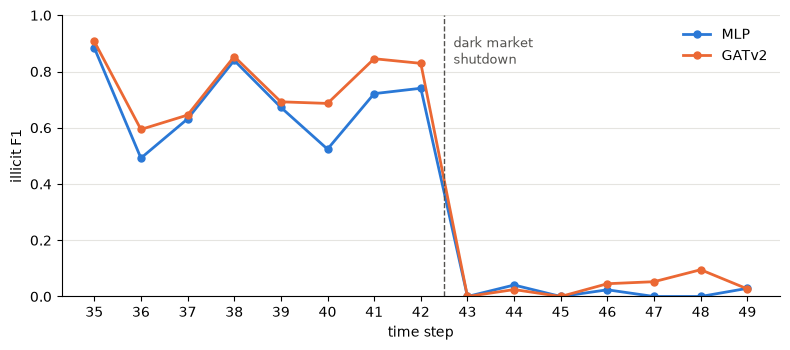

illicit transactions per test step: [182, 33, 40, 111, 81, 112, 116, 239, 24, 24, 5, 2, 22, 36, 56]


In [26]:
test_steps = np.arange(35, 50)


def f1_per_step(pred):
    scores = []
    for t in test_steps:
        idx = np.nonzero(known & (time_step == t))[0]
        scores.append(f1_score(y_tx[idx], pred[idx], zero_division=0))
    return scores


illicit_per_step = [int(((time_step == t) & (y_tx == 1)).sum()) for t in test_steps]

fig, ax = plt.subplots(figsize=(8, 3.6))
for name, color in (("MLP", "#2a78d6"), ("GATv2", "#eb6834")):
    scores = f1_per_step(local_predictions[name])
    ax.plot(
        test_steps,
        scores,
        color=color,
        linewidth=2,
        marker="o",
        markersize=5,
        label=name,
    )
ax.axvline(42.5, color="#52514e", linewidth=1, linestyle="--")
ax.text(42.7, 0.93, "dark market\nshutdown", color="#52514e", fontsize=9, va="top")
ax.set_xlabel("time step")
ax.set_ylabel("illicit F1")
ax.set_ylim(0, 1)
ax.set_xticks(test_steps)
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()
print("illicit transactions per test step:", illicit_per_step)

Both models do well up to time step 42, then collapse: from time step 43 on, they detect almost no illicit transactions. Weber et al. relate this to the shutdown of a large dark market at that time. The illicit activity that followed does not look like anything in the training data, and neither the features nor the neighbourhood help with that.

Most of the test set's illicit transactions (914 of 1,083) are before the shutdown, which is why the overall scores above still look reasonable.
A graph model does not solve this kind of drift: in production, a detector has to be monitored and retrained as new labels come in.

## 3. Network intrusion detection (edge classification)

Network monitoring tools summarize traffic as **flow records** (NetFlow, IPFIX): one record per connection, with the two endpoints, the protocol, byte and packet counts, TCP flags, duration, and so on.
Hosts are nodes and flows are edges, so classifying flows is an edge classification problem.

We use **NF-UNSW-NB15-v3** ([Luay et al., 2025](https://arxiv.org/abs/2503.04404)), the NetFlow version of the UNSW-NB15 testbed ([Moustafa & Slay, 2015](https://doi.org/10.1109/MilCIS.2015.7348942)).
It has 2.4 million flows, 5.4% of which belong to nine attack families. The University of Queensland publishes it; we download the Parquet copy of the [`keys-i/netFlow`](https://huggingface.co/datasets/keys-i/netFlow) Hugging Face mirror, which checked the official checksums before conversion (105 MB).

In [27]:
from mlx_graphs.datasets.utils import download

netflow_dir = os.path.join(".mlx_graphs_data", "nf_unsw_nb15_v3")
netflow_file = os.path.join(netflow_dir, "NF-UNSW-NB15-v3.parquet")
if not os.path.exists(netflow_file):
    os.makedirs(netflow_dir, exist_ok=True)
    download(
        "https://huggingface.co/datasets/keys-i/netFlow/resolve/main/data/NF-UNSW-NB15-v3.parquet",
        netflow_file,
        log=False,
    )

columns = [
    "FLOW_START_MILLISECONDS", "IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_DST_PORT",
    "PROTOCOL", "L7_PROTO", "IN_BYTES", "OUT_BYTES", "IN_PKTS", "OUT_PKTS",
    "TCP_FLAGS", "FLOW_DURATION_MILLISECONDS", "MIN_TTL", "Label", "Attack",
]  # fmt: skip
flows = pd.read_parquet(netflow_file, columns=columns)
flows = flows.sort_values("FLOW_START_MILLISECONDS", kind="stable").reset_index(
    drop=True
)
flows["Attack"].value_counts().to_frame("flows").T

Attack,Benign,Exploits,Fuzzers,Generic,Reconnaissance,DoS,Backdoor,Shellcode,Analysis,Worms
flows,2237731,42748,33816,19651,17074,5980,4659,2381,1226,158


### Beware of shortcuts

Before training anything, look at which hosts send the attacks, and at the IP time-to-live (TTL) of the packets:

In [28]:
by_source = flows.groupby("IPV4_SRC_ADDR")["Label"].agg(
    flows="size", attack_rate="mean"
)
by_ttl = flows.groupby("MIN_TTL")["Label"].agg(flows="size", attack_rate="mean")
display(by_source.sort_values("flows", ascending=False).head(8))
display(by_ttl.sort_values("flows", ascending=False).head(4))

,flows,attack_rate
IPV4_SRC_ADDR,,
59.166.0.2,225316,0.0
59.166.0.4,224942,0.0
59.166.0.1,224766,0.0
59.166.0.0,224274,0.0
59.166.0.3,223608,0.0
59.166.0.5,222835,0.0
59.166.0.9,215681,0.0
59.166.0.8,215238,0.0


,flows,attack_rate
MIN_TTL,,
31,2205019,0.000000
254,95806,0.999937
62,31694,1.000000
0,27147,0.007220


In this testbed every attack comes from four machines (`175.45.176.0`–`3`), and their packets have TTLs (62 and 254) that benign traffic never has.
A model given the IP addresses or the TTL learns to recognize these four machines, scores almost perfectly, and is useless on any other network.
This kind of shortcut is common in intrusion detection benchmarks, so we never use addresses or TTLs as features.

Instead we keep the basic fields of NetFlow v5/v9, which almost any router exports: protocol, application protocol, destination port, byte and packet counts, TCP flags and duration.
Counts are heavy-tailed, so we log-scale them, and TCP flags become 8 bits.

In [29]:
def flow_features(flows):
    counts = flows[
        [
            "IN_BYTES",
            "OUT_BYTES",
            "IN_PKTS",
            "OUT_PKTS",
            "FLOW_DURATION_MILLISECONDS",
            "L4_DST_PORT",
        ]
    ].to_numpy(np.float64)
    tcp_flags = (flows["TCP_FLAGS"].to_numpy()[:, None] >> np.arange(8)) & 1
    protocol = np.stack(
        [flows["PROTOCOL"] == p for p in (6, 17, 1)], axis=1
    )  # TCP, UDP, ICMP
    protocol = np.concatenate([protocol, ~protocol.any(1, keepdims=True)], axis=1)
    well_known_port = (flows["L4_DST_PORT"].to_numpy() < 1024)[:, None]
    l7 = flows["L7_PROTO"].to_numpy().astype(int)
    top_l7 = pd.Series(l7).value_counts().index[:15].to_numpy()
    l7 = l7[:, None] == top_l7[None, :]
    l7 = np.concatenate([l7, ~l7.any(1, keepdims=True)], axis=1)
    return np.concatenate(
        [np.log1p(counts), tcp_flags, protocol, well_known_port, l7], axis=1
    ).astype(np.float32)


attack_classes = ["Benign"] + sorted(set(flows["Attack"]) - {"Benign"})
flow_labels = (
    flows["Attack"].map({c: i for i, c in enumerate(attack_classes)}).to_numpy()
)
flow_x = flow_features(flows)
flow_x.shape

(2365424, 35)

### From flows to graphs

We cut the time-ordered flows into windows of 1,024 consecutive flows (a few seconds to a few minutes of traffic) and turn each window into a graph: the hosts seen in the window are the nodes, and every flow is a directed edge carrying its features and its label.
Small graphs keep the context local in time and can be batched with a `Dataloader`.

Hosts get no identity features, only what they did in the window: how many flows they sent and received, to how many distinct peers, and how many distinct services (host and port pairs) they used.

The split is chronological: the first 60% of the windows for training, the next 10% for validation and the last 30% for testing.

In [30]:
WINDOW = 1024


def host_statistics(edge_index, dst_port, num_hosts):
    src, dst = edge_index
    peers = np.unique(edge_index, axis=1)
    services_used = np.unique(np.stack([src, dst_port]), axis=1)[0]
    services_offered = np.unique(np.stack([dst, dst_port]), axis=1)[0]
    stats = [src, dst, peers[0], peers[1], services_used, services_offered]
    return np.log1p(np.stack([np.bincount(s, minlength=num_hosts) for s in stats], 1))


num_windows = len(flows) // WINDOW
num_train, num_val = int(0.6 * num_windows), int(0.1 * num_windows)

# standardize the features with training statistics only
train_rows = num_train * WINDOW
flow_x = (flow_x - flow_x[:train_rows].mean(0)) / (flow_x[:train_rows].std(0) + 1e-6)

src_ip, dst_ip = flows["IPV4_SRC_ADDR"].to_numpy(), flows["IPV4_DST_ADDR"].to_numpy()
dst_port = flows["L4_DST_PORT"].to_numpy()
windows = []
for w in range(num_windows):
    rows = slice(w * WINDOW, (w + 1) * WINDOW)
    hosts, endpoints = np.unique(
        np.concatenate([src_ip[rows], dst_ip[rows]]), return_inverse=True
    )
    edge_index = endpoints.reshape(2, -1).astype(np.int32)
    windows.append(
        GraphData(
            edge_index=mx.array(edge_index),
            node_features=mx.array(
                host_statistics(edge_index, dst_port[rows], len(hosts)),
                dtype=mx.float32,
            ),
            edge_features=mx.array(flow_x[rows]),
            edge_labels=mx.array(flow_labels[rows].astype(np.int32)),
        )
    )

train_windows = windows[:num_train]
val_windows = windows[num_train : num_train + num_val]
test_windows = windows[num_train + num_val :]
del flows, flow_x, src_ip, dst_ip  # the graphs hold everything we need from now on
print(
    f"{len(windows)} windows: {len(train_windows)} train, "
    f"{len(val_windows)} val, {len(test_windows)} test"
)
windows[0]

2309 windows: 1385 train, 230 val, 694 test


GraphData(
	edge_index(shape=(2, 1024), int32)
	node_features(shape=(38, 6), float32)
	edge_features(shape=(1024, 35), float32)
	edge_labels(shape=(1024,), int32))

### E-GraphSAGE

[E-GraphSAGE](https://arxiv.org/abs/2103.16329) (Lo et al., NOMS 2022) adapts GraphSAGE to graphs whose information is on the edges. A host aggregates the flows it takes part in:

$$
m_v = \operatorname{mean}_{(u, v) \in E} \; W_m [h_u \,\|\, e_{uv}], \qquad h_v' = \operatorname{ReLU}(W_a [h_v \,\|\, m_v])
$$

and a flow is classified from its two endpoints.
We follow the paper with two changes: messages go both ways (a host sees the flows it sends and receives, with a flag giving the direction), and the classifier also reads the flow's own features, since many flows in a window share the same pair of hosts.

To write the layer, we subclass `MessagePassing` and override `message`. `propagate` passes every entry of `message_kwargs` to `message`, together with the features of the source and destination nodes of each edge, and aggregates the result with `aggr="mean"`.
Since the message is not a weighted sum of neighbour features, the layer uses the gather-scatter path of mlx-graphs rather than the fused kernel, so it does not take the `@fused_message_passing` decorator.

In [31]:
class EGraphSAGEConv(MessagePassing):
    def __init__(self, node_dim, edge_dim, out_dim):
        super().__init__(aggr="mean")
        self.message_proj = Linear(node_dim + edge_dim, out_dim)
        self.update_proj = Linear(node_dim + out_dim, out_dim)

    def __call__(self, edge_index, node_features, edge_features):
        neighbours = self.propagate(
            edge_index, node_features, message_kwargs={"edge_features": edge_features}
        )
        return nn.relu(
            self.update_proj(mx.concatenate([node_features, neighbours], axis=-1))
        )

    def message(self, src_features, dst_features, edge_features):
        return self.message_proj(mx.concatenate([src_features, edge_features], axis=-1))


class EGraphSAGE(nn.Module):
    def __init__(
        self, node_dim, edge_dim, hidden, num_classes, num_layers=2, dropout=0.2
    ):
        super().__init__()
        dims = [node_dim] + [hidden] * num_layers
        # edge_dim + 1: the direction flag
        self.convs = [
            EGraphSAGEConv(i, edge_dim + 1, o) for i, o in zip(dims[:-1], dims[1:])
        ]
        self.flow_proj = Linear(edge_dim, hidden)
        self.classifier = [Linear(3 * hidden, hidden), Linear(hidden, num_classes)]
        self.dropout = nn.Dropout(dropout)

    def __call__(self, edge_index, node_features, edge_features):
        num_flows = edge_index.shape[1]
        both_ways = mx.concatenate([edge_index, edge_index[::-1]], axis=1)
        direction = mx.concatenate([mx.zeros((num_flows, 1)), mx.ones((num_flows, 1))])
        both_features = mx.concatenate(
            [mx.concatenate([edge_features, edge_features]), direction], axis=-1
        )
        h = node_features
        for conv in self.convs:
            h = self.dropout(conv(both_ways, h, both_features))
        src, dst = edge_index
        z = mx.concatenate(
            [h[src], h[dst], nn.relu(self.flow_proj(edge_features))], axis=-1
        )
        z = self.dropout(nn.relu(self.classifier[0](z)))
        return self.classifier[1](z)

We compare it with two baselines that classify each flow on its own: an MLP on the flow features, and the same MLP given the statistics of the two hosts as extra inputs. The second one tells us how much of E-GraphSAGE's gain hand-made host features would give.

In [32]:
class FlowMLP(nn.Module):
    def __init__(self, edge_dim, hidden, num_classes, node_dim=0, dropout=0.2):
        super().__init__()
        self.use_hosts = node_dim > 0
        self.lin1 = Linear(edge_dim + 2 * node_dim, hidden)
        self.lin2 = Linear(hidden, hidden)
        self.out = Linear(hidden, num_classes)
        self.dropout = nn.Dropout(dropout)

    def __call__(self, edge_index, node_features, edge_features):
        h = edge_features
        if self.use_hosts:
            src, dst = edge_index
            h = mx.concatenate([h, node_features[src], node_features[dst]], axis=-1)
        h = self.dropout(nn.relu(self.lin1(h)))
        h = self.dropout(nn.relu(self.lin2(h)))
        return self.out(h)

Benign flows outnumber the rarest attack (worms) 27,000 to 1 in the training windows. Weighting each class by the inverse of its frequency would make the loss chase a few dozen worm flows, so we use the square root of the inverse frequency, a common compromise.

We report two views of the test windows:

* **detection**: attack or benign, with the number of false alarms (benign flows flagged as attacks) and missed attacks, which is what an analyst on call cares about;
* **attack type**: the macro F1 over the 10 classes, which tells the analyst what kind of attack to respond to.

In [33]:
train_counts = np.bincount(flow_labels[:train_rows], minlength=len(attack_classes))
flow_class_weights = mx.array(
    np.sqrt(train_counts.sum() / train_counts), dtype=mx.float32
)
flow_class_weights = flow_class_weights / flow_class_weights.mean()


def predict_flows(model, graphs):
    model.eval()
    preds, labels = [], []
    for batch in Dataloader(graphs, batch_size=128):
        logits = model(batch.edge_index, batch.node_features, batch.edge_features)
        preds.append(np.array(mx.argmax(logits, axis=-1)))
        labels.append(np.array(batch.edge_labels))
    return np.concatenate(preds), np.concatenate(labels)


def train_flows(make_model, seed, epochs=30, lr=3e-3):
    mx.random.seed(seed)
    model = make_model()
    mx.eval(model.parameters())
    optimizer = optim.AdamW(learning_rate=lr, weight_decay=1e-4, bias_correction=True)

    def loss_fn(model, batch):
        logits = model(batch.edge_index, batch.node_features, batch.edge_features)
        w = flow_class_weights[batch.edge_labels]
        return mx.sum(nn.losses.cross_entropy(logits, batch.edge_labels) * w) / mx.sum(
            w
        )

    loss_and_grad = nn.value_and_grad(model, loss_fn)
    best_val, best_test = -1.0, None
    for epoch in range(epochs):
        model.train()
        for batch in Dataloader(train_windows, batch_size=32, shuffle=True):
            loss, grads = loss_and_grad(model, batch)
            optimizer.update(model, grads)
            mx.eval(model.parameters(), optimizer.state)
        val_pred, val_true = predict_flows(model, val_windows)
        val_f1 = f1_score(val_true, val_pred, average="macro")
        if val_f1 > best_val:
            best_val, best_test = val_f1, predict_flows(model, test_windows)
    return best_test


flow_dim = windows[0].edge_features.shape[1]
host_dim = windows[0].node_features.shape[1]
n_classes = len(attack_classes)
nids_models = {
    "MLP": lambda: FlowMLP(flow_dim, 128, n_classes),
    "MLP + host statistics": lambda: FlowMLP(
        flow_dim, 128, n_classes, node_dim=host_dim
    ),
    "E-GraphSAGE": lambda: EGraphSAGE(host_dim, flow_dim, 128, n_classes),
}

nids_rows, nids_predictions = {}, {}
for name, make_model in nids_models.items():
    start = time.perf_counter()
    runs = [train_flows(make_model, seed) for seed in range(NUM_SEEDS)]
    nids_predictions[name] = runs[0]
    nids_rows[name] = {
        "detection F1": mean_std([f1_score(y > 0, p > 0) for p, y in runs]),
        "false alarms": round(np.mean([((p > 0) & (y == 0)).sum() for p, y in runs])),
        "missed attacks": round(np.mean([((p == 0) & (y > 0)).sum() for p, y in runs])),
        "attack type macro F1": mean_std(
            [f1_score(y, p, average="macro") for p, y in runs]
        ),
        "seconds per run": round((time.perf_counter() - start) / NUM_SEEDS, 1),
    }
print(
    f"{len(nids_predictions['MLP'][1])} test flows, "
    f"{(nids_predictions['MLP'][1] > 0).sum()} attacks"
)
pd.DataFrame(nids_rows).T

710656 test flows, 62619 attacks


,detection F1,false alarms,missed attacks,attack type macro F1,seconds per run
MLP,0.992 ± 0.000,644,409,0.507 ± 0.004,6.3
MLP + host statistics,0.996 ± 0.001,405,109,0.501 ± 0.004,6.4
E-GraphSAGE,0.996 ± 0.001,501,36,0.484 ± 0.010,15.0


All three models separate attacks from benign traffic with an F1 above 0.99, but the error counts tell them apart. Among the 62,619 attacks in the 710,656 test flows, the MLP misses 409 and raises 644 false alarms.
Giving it the statistics of the two hosts cuts the missed attacks to 109 and the false alarms to 405. E-GraphSAGE, which learns its own summary of each host's traffic, misses only 36 attacks, 11 times fewer than the MLP, with a fifth fewer false alarms (501).
A stealthy attack flow can look benign on its own, but it comes from a host that does other suspicious things in the same window.

Two caveats. In this testbed the attacking machines send nothing but attacks, which makes context unusually informative; on a real network, a compromised machine also carries legitimate traffic. And context does not help to name the attack: the attack type macro F1 is a little lower with it (0.48–0.50 against 0.51).

In [34]:
pd.DataFrame(
    {
        name: f1_score(y, p, average=None, labels=range(n_classes))
        for name, (p, y) in nids_predictions.items()
    },
    index=attack_classes,
).round(3)

,MLP,MLP + host statistics,E-GraphSAGE
Benign,0.999,1.000,1.000
Analysis,0.342,0.365,0.346
Backdoor,0.046,0.010,0.009
DoS,0.118,0.178,0.174
Exploits,0.669,0.677,0.662
Fuzzers,0.726,0.731,0.672
Generic,0.780,0.778,0.769
Reconnaissance,0.670,0.623,0.637
Shellcode,0.480,0.464,0.498
Worms,0.206,0.190,0.136


All models recognize Generic, Fuzzers, Exploits and Reconnaissance flows reasonably well, while Backdoor, DoS, Worms and Analysis flows are mostly confused with other attacks: with these few NetFlow fields, their flows look alike.
Host context helps DoS and Analysis a little, and hurts Backdoor and Worms, the rarest attack in the training windows. Naming the attack needs richer flow features (NetFlow v3 has 53 of them) or payload inspection more than it needs the graph.

## 4. Malware classification (graph classification)

A program's **function call graph** has one node per function and one edge per call. Its shape survives a lot of the obfuscation that defeats byte signatures, such as renaming, string encryption and packing of resources.

[MalNet](https://arxiv.org/abs/2011.07682) (Freitas et al., NeurIPS 2021 Datasets) extracted the call graphs of 1.2 million Android apps. We use **MalNet-Tiny**, 5,000 graphs of at most 5,000 nodes in five balanced classes: benign apps and four malware types (adware, ad display, downloader, trojan), with the official train/validation/test split.

mlx-graphs does not ship MalNet, which is a good opportunity to write a `Dataset`. A subclass implements `download`, which saves the raw files in `self.raw_path`, and `process`, which fills `self.graphs` with `GraphData` objects. The base class runs them on the first use only, and caches the processed graphs on disk.

In [35]:
from mlx_graphs.datasets import Dataset
from mlx_graphs.datasets.utils import extract_archive
from mlx_graphs.utils import scatter


def local_degree_profile(edge_index, num_nodes):
    # [degree, min, max, mean and std of the neighbours' degrees], log-scaled
    src, dst = mx.array(edge_index[0]), mx.array(edge_index[1])
    deg = scatter(mx.ones(src.shape), dst, num_nodes)
    neighbour_deg = deg[src]
    mean = scatter(neighbour_deg, dst, num_nodes, aggr="mean")
    mean_sq = scatter(neighbour_deg**2, dst, num_nodes, aggr="mean")
    profile = [
        deg,
        scatter(neighbour_deg, dst, num_nodes, aggr="min"),
        scatter(neighbour_deg, dst, num_nodes, aggr="max"),
        mean,
        mx.sqrt(mx.maximum(mean_sq - mean**2, 0)),
    ]
    return mx.log1p(mx.stack(profile, axis=1))


class MalNetTiny(Dataset):
    graphs_url = "http://malnet.cc.gatech.edu/graph-data/malnet-graphs-tiny.tar.gz"
    split_url = "http://malnet.cc.gatech.edu/split-info/split_info_tiny.zip"
    classes = ["addisplay", "adware", "benign", "downloader", "trojan"]

    def __init__(self, base_dir=None):
        super().__init__(name="malnet_tiny", base_dir=base_dir)

    def download(self):
        for url in (self.graphs_url, self.split_url):
            path = download(url, os.path.join(self.raw_path, os.path.basename(url)))
            extract_archive(path, self.raw_path)

    def split_files(self):
        folder = os.path.join(self.raw_path, "split_info_tiny", "type")
        return {s: os.path.join(folder, f"{s}.txt") for s in ("train", "val", "test")}

    def process(self):
        # graphs are stored in split order: train, then val, then test
        self.graphs = []
        for split_file in self.split_files().values():
            for entry in open(split_file).read().split():  # "<type>/<family>/<sha256>"
                path = os.path.join(
                    self.raw_path, "malnet-graphs-tiny", entry + ".edgelist"
                )
                edges = (
                    pd.read_csv(path, sep="\t", comment="#", header=None).to_numpy().T
                )
                # node ids are not contiguous: relabel them 0..num_nodes-1
                ids, edges = np.unique(edges, return_inverse=True)
                edges = edges.reshape(2, -1).astype(np.int32)
                # call graphs are directed; we let information flow both ways
                edges = np.concatenate([edges, edges[::-1]], axis=1)
                self.graphs.append(
                    GraphData(
                        edge_index=mx.array(edges),
                        node_features=local_degree_profile(edges, len(ids)),
                        graph_labels=mx.array(
                            [self.classes.index(entry.split("/")[0])]
                        ),
                    )
                )

    def split(self, name):
        sizes = {s: len(open(f).read().split()) for s, f in self.split_files().items()}
        start = {
            "train": 0,
            "val": sizes["train"],
            "test": sizes["train"] + sizes["val"],
        }
        return self[start[name] : start[name] + sizes[name]]


malnet = MalNetTiny()
malnet_train, malnet_val, malnet_test = (
    malnet.split(s) for s in ("train", "val", "test")
)
num_nodes = np.array([g.num_nodes for g in malnet])
print(
    f"{len(malnet_train)} train, {len(malnet_val)} val, {len(malnet_test)} test graphs"
)
print(f"nodes per graph: mean {num_nodes.mean():.0f}, max {num_nodes.max()}")
malnet[0]

Loading malnet_tiny data ... 

Done
3500 train, 500 val, 1000 test graphs
nodes per graph: mean 1410, max 4994


GraphData(
	edge_index(shape=(2, 7152), int32)
	node_features(shape=(1611, 5), float32)
	graph_labels(shape=(1,), int32))

Call graphs come without node features: a function is anonymous. A standard input for such graphs is the **local degree profile** ([Cai & Wang, 2018](https://arxiv.org/abs/1811.03508)), which describes each node by its degree and the minimum, maximum, mean and standard deviation of its neighbours' degrees. We compute it in `process` with `scatter`, so it is cached with the graphs.

### GIN

[GIN](https://arxiv.org/abs/1810.00826) (Xu et al., 2019) sums the neighbours' embeddings and passes the result through an MLP, which makes it as good at telling graph structures apart as message passing can be. We stack 5 `GINConv` layers with residual connections and average the node embeddings of each graph with `global_mean_pool`.

In [36]:
from mlx_graphs.nn import GINConv, global_mean_pool


def gin_mlp(dim):
    return nn.Sequential(
        Linear(dim, dim), nn.BatchNorm(dim), nn.ReLU(), Linear(dim, dim)
    )


class GIN(nn.Module):
    def __init__(self, in_dim, hidden, num_classes, num_layers=5):
        super().__init__()
        self.encoder = Linear(in_dim, hidden)
        self.convs = [GINConv(gin_mlp(hidden)) for _ in range(num_layers)]
        self.norms = [nn.BatchNorm(hidden) for _ in range(num_layers)]
        self.head = nn.Sequential(
            Linear(hidden, hidden), nn.ReLU(), Linear(hidden, num_classes)
        )

    def __call__(self, edge_index, x, batch_indices, num_graphs):
        h = self.encoder(x)
        for conv, norm in zip(self.convs, self.norms):
            h = h + nn.relu(norm(conv(edge_index, h)))
        return self.head(global_mean_pool(h, batch_indices))

### GraphGPS with linear attention

Five rounds of message passing only see five hops, while call graphs have up to 5,000 nodes. [GraphGPS](https://arxiv.org/abs/2205.12454) (Rampášek et al., NeurIPS 2022) runs, in every layer, a message passing layer and a global attention among all the nodes of the graph side by side, and sums them. On MalNet-Tiny the paper replaced softmax attention, whose cost grows with the square of the number of nodes, by a linear one.

We use the linear attention of [Katharopoulos et al. (2020)](https://arxiv.org/abs/2006.16236). With a positive feature map $\phi(x) = \operatorname{elu}(x) + 1$, the attention output of node $i$ is

$$
o_i = \frac{\phi(q_i)^\top \sum_j \phi(k_j)\, v_j^\top}{\phi(q_i)^\top \sum_j \phi(k_j)},
$$

and both sums are computed once per graph, so the cost is linear in the number of nodes. With batches of graphs, each node must only attend to the nodes of its own graph: `to_dense_batch` pads the nodes into a `[num_graphs, max_nodes, ...]` array with a mask, and batched matrix products compute the per-graph sums.

In [37]:
from mlx_graphs.utils import to_dense_batch


def positive_feature_map(x):
    # elu(x) + 1, written so that the gradient stays finite for large x: in
    # nn.elu the unused exp(x) branch overflows for x > 88 and 0 * inf = nan
    return mx.where(x > 0, x + 1, mx.exp(mx.minimum(x, 0)))


class LinearAttention(nn.Module):
    def __init__(self, dim, heads=4):
        super().__init__()
        self.heads, self.head_dim = heads, dim // heads
        self.qkv = Linear(dim, 3 * dim)
        self.out = Linear(dim, dim)

    def __call__(self, x, batch_indices):
        n = x.shape[0]
        # pad the nodes of each graph: [num_graphs, max_nodes, 3 * dim]
        qkv, mask = to_dense_batch(self.qkv(x), batch_indices)
        b, m = mask.shape
        qkv = qkv.reshape(b, m, 3, self.heads, self.head_dim).transpose(2, 0, 3, 1, 4)
        q, k, v = positive_feature_map(qkv[0]), positive_feature_map(qkv[1]), qkv[2]
        k = k * mask[:, None, :, None]  # padding nodes contribute nothing
        kv = k.swapaxes(-1, -2) @ v  # sum_j phi(k_j) v_j^T, per graph and head
        k_sum = k.sum(axis=2, keepdims=True)  # sum_j phi(k_j)
        out = (q @ kv) / ((q * k_sum).sum(axis=-1, keepdims=True) + 1e-6)
        out = out.transpose(0, 2, 1, 3).reshape(b, m, -1)  # [graphs, nodes, dim]
        # back to one row per node: node i sits at (its graph, its rank in the graph)
        counts = mask.sum(axis=1)
        rank = mx.arange(n) - (mx.cumsum(counts) - counts)[batch_indices]
        return self.out(out[batch_indices, rank])


class GPSLayer(nn.Module):
    def __init__(self, dim, heads=4):
        super().__init__()
        self.local = GINConv(gin_mlp(dim))
        self.attention = LinearAttention(dim, heads)
        self.norm_local, self.norm_attention, self.norm_ffn = (
            nn.BatchNorm(dim) for _ in range(3)
        )
        self.ffn = nn.Sequential(Linear(dim, 2 * dim), nn.ReLU(), Linear(2 * dim, dim))

    def __call__(self, edge_index, h, batch_indices):
        h_local = self.norm_local(h + self.local(edge_index, h))
        h_global = self.norm_attention(h + self.attention(h, batch_indices))
        h = h_local + h_global
        return self.norm_ffn(h + self.ffn(h))


class GPS(nn.Module):
    def __init__(self, in_dim, hidden, num_classes, num_layers=5, heads=4):
        super().__init__()
        self.encoder = Linear(in_dim, hidden)
        self.layers = [GPSLayer(hidden, heads) for _ in range(num_layers)]
        self.head = nn.Sequential(
            Linear(hidden, hidden), nn.ReLU(), Linear(hidden, num_classes)
        )

    def __call__(self, edge_index, x, batch_indices, num_graphs):
        h = self.encoder(x)
        for layer in self.layers:
            h = layer(edge_index, h, batch_indices)
        return self.head(global_mean_pool(h, batch_indices))

### Training

We train with mini-batches of 16 graphs for 20 epochs and evaluate on the test set at the epoch with the best validation accuracy. Training is the slowest part of this notebook, so we use a single seed here.

In [38]:
def malnet_logits(model, batch):
    return model(
        batch.edge_index, batch.node_features, batch.batch_indices, batch.num_graphs
    )


def malnet_predict(model, graphs):
    model.eval()
    preds, labels = [], []
    for batch in Dataloader(graphs, batch_size=64):
        preds.append(np.array(mx.argmax(malnet_logits(model, batch), axis=-1)))
        labels.append(np.array(batch.graph_labels).reshape(-1))
    return np.concatenate(preds), np.concatenate(labels)


def train_malnet(model, epochs=20, lr=1e-3, seed=0):
    mx.random.seed(seed)
    mx.eval(model.parameters())
    optimizer = optim.AdamW(learning_rate=lr, weight_decay=1e-4, bias_correction=True)

    def loss_fn(model, batch):
        logits = malnet_logits(model, batch)
        return mx.mean(nn.losses.cross_entropy(logits, batch.graph_labels.reshape(-1)))

    loss_and_grad = nn.value_and_grad(model, loss_fn)
    best_val, best_test, history = -1.0, None, []
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        for batch in Dataloader(malnet_train, batch_size=16, shuffle=True):
            loss, grads = loss_and_grad(model, batch)
            optimizer.update(model, grads)
            mx.eval(model.parameters(), optimizer.state)
        val_pred, val_true = malnet_predict(model, malnet_val)
        val_acc = (val_pred == val_true).mean()
        history.append(val_acc)
        if val_acc > best_val:
            best_val, best_test = val_acc, malnet_predict(model, malnet_test)
        if epoch % 5 == 0:
            print(
                f"epoch {epoch:2d} | val accuracy {val_acc:.3f} | "
                f"{time.perf_counter() - start:.0f}s"
            )
    return best_test, history


mx.random.seed(0)
gin_test, gin_history = train_malnet(GIN(5, 64, len(MalNetTiny.classes)))

epoch  5 | val accuracy 0.702 | 37s


epoch 10 | val accuracy 0.730 | 73s


epoch 15 | val accuracy 0.706 | 109s


epoch 20 | val accuracy 0.802 | 145s


In [39]:
mx.random.seed(0)
gps_test, gps_history = train_malnet(GPS(5, 64, len(MalNetTiny.classes)))

epoch  5 | val accuracy 0.788 | 167s


epoch 10 | val accuracy 0.748 | 327s


epoch 15 | val accuracy 0.866 | 495s


epoch 20 | val accuracy 0.884 | 671s


In [40]:
malnet_rows = {}
for name, (pred, true) in (("GIN", gin_test), ("GraphGPS", gps_test)):
    row = {"test accuracy": round((pred == true).mean(), 3)}
    for c, cls in enumerate(MalNetTiny.classes):
        row[f"{cls} recall"] = round((pred[true == c] == c).mean(), 3)
    malnet_rows[name] = row
pd.DataFrame(malnet_rows).T

,test accuracy,addisplay recall,adware recall,benign recall,downloader recall,trojan recall
GIN,0.776,0.505,0.905,0.81,0.995,0.665
GraphGPS,0.867,0.930,0.915,0.82,0.995,0.675


GraphGPS reaches 86.7% test accuracy against 77.6% for GIN. Most of the gain is on ad display apps, of which GraphGPS recognizes 93% against 51% for GIN. On benign apps, which decide how many false alarms a detector raises on legitimate software, the two models are level (82% and 81%).
Global attention lets every function see the whole program, which five hops of message passing cannot. The price is time: an epoch of GraphGPS takes about 4.6 times as long as one of GIN (34 s against 7 s).

Validation accuracy is noisy from one epoch to the next (GraphGPS drops from 0.79 at epoch 5 to 0.75 at epoch 10, GIN from 0.73 at epoch 10 to 0.71 at epoch 15), which is why we evaluate the epoch chosen on the validation set rather than the last one.
These are single runs of 20 epochs. The GraphGPS paper reports about 89% for GIN and 93% for GraphGPS (with GatedGCN layers and Performer attention) after much longer training, so both models here have room to improve.

## Takeaways

* **Context helps when the label depends on who you interact with.** Attention GNNs found about 0.1 more illicit F1 than an MLP on Bitcoin transactions, E-GraphSAGE missed 11 times fewer attacks than a per-flow classifier, and global attention gained 9 points of accuracy on malware call graphs.
* **Attention layers were the strongest on two of the three tasks where we tried them** (GATv2 and the Graph Transformer on Elliptic's raw features, GraphGPS on MalNet), at a higher cost per epoch.
On provenance graphs, the linear Velox found the same three attacks as the attention-based Orthrus with a higher precision, and trained 10 times faster: always compare a GNN with a baseline that ignores the graph.
* **Labels are not always needed.** Trained only to predict the type of benign system events, Velox and Orthrus ranked the payloads of the CADETS attacks among their first alerts.
* **Evaluate the way the model will be used.** Split by time, learn features and set thresholds on data without attacks, never use identifiers such as IP addresses or TTLs as features, and average several seeds: random splits and shortcut features make security benchmarks look solved.
* **No model survives a change of adversary on its own.** After the dark market shutdown, every model on Elliptic failed; detection models need monitoring and retraining.
* **New layers are short to write with mlx-graphs:** keep the recent neighbors of every node of an event stream with `LastNeighborLoader` (Orthrus), override `message` for edge-feature messages (E-GraphSAGE), reuse the fused weighted sum for spectral filters (BWGNN), and use `scatter` and `to_dense_batch` for node statistics and per-graph attention (GraphGPS). A `Dataset` subclass with `download` and `process` handles new data sources.

## References

* B. Jiang et al., [ORTHRUS: Achieving High Quality of Attribution in Provenance-based Intrusion Detection Systems](https://www.usenix.org/conference/usenixsecurity25/presentation/jiang-baoxiang), USENIX Security 2025.
* T. Bilot et al., [Sometimes Simpler is Better: A Comprehensive Analysis of State-of-the-Art Provenance-Based Intrusion Detection Systems](https://www.usenix.org/conference/usenixsecurity25/presentation/bilot), USENIX Security 2025.
* T. Mikolov et al., [Distributed Representations of Words and Phrases and their Compositionality](https://arxiv.org/abs/1310.4546), NeurIPS 2013.
* M. Weber et al., [Anti-Money Laundering in Bitcoin: Experimenting with Graph Convolutional Networks for Financial Forensics](https://arxiv.org/abs/1908.02591), KDD Workshop on Anomaly Detection in Finance, 2019.
* T. Kipf, M. Welling, [Semi-Supervised Classification with Graph Convolutional Networks](https://arxiv.org/abs/1609.02907), ICLR 2017.
* W. Hamilton, R. Ying, J. Leskovec, [Inductive Representation Learning on Large Graphs](https://arxiv.org/abs/1706.02216), NeurIPS 2017.
* S. Brody, U. Alon, E. Yahav, [How Attentive are Graph Attention Networks?](https://arxiv.org/abs/2105.14491), ICLR 2022.
* Y. Shi et al., [Masked Label Prediction: Unified Message Passing Model for Semi-Supervised Classification](https://arxiv.org/abs/2009.03509), IJCAI 2021.
* J. Tang, J. Li, Z. Gao, J. Li, [Rethinking Graph Neural Networks for Anomaly Detection](https://arxiv.org/abs/2205.15508), ICML 2022.
* W. W. Lo et al., [E-GraphSAGE: A Graph Neural Network based Intrusion Detection System for IoT](https://arxiv.org/abs/2103.16329), NOMS 2022.
* M. Luay et al., [Temporal Analysis of NetFlow Datasets for Network Intrusion Detection Systems](https://arxiv.org/abs/2503.04404), 2025.
* N. Moustafa, J. Slay, [UNSW-NB15: a comprehensive data set for network intrusion detection systems](https://doi.org/10.1109/MilCIS.2015.7348942), MilCIS 2015.
* S. Freitas et al., [A Large-Scale Database for Graph Representation Learning](https://arxiv.org/abs/2011.07682), NeurIPS 2021 Datasets and Benchmarks.
* C. Cai, Y. Wang, [A Simple yet Effective Baseline for Non-Attributed Graph Classification](https://arxiv.org/abs/1811.03508), 2018.
* K. Xu, W. Hu, J. Leskovec, S. Jegelka, [How Powerful are Graph Neural Networks?](https://arxiv.org/abs/1810.00826), ICLR 2019.
* L. Rampášek et al., [Recipe for a General, Powerful, Scalable Graph Transformer](https://arxiv.org/abs/2205.12454), NeurIPS 2022.
* A. Katharopoulos et al., [Transformers are RNNs: Fast Autoregressive Transformers with Linear Attention](https://arxiv.org/abs/2006.16236), ICML 2020.